# 07 · People in the blind spots

Notebook 03 showed the scorecard misses a lot of hospitals. This puts people behind that
gap: how many New Mexicans live in a county with no CMS-rated hospital.

We join 2024 Census county population to the hospital list. "No CMS-rated hospital" means
the county has no hospital in the CMS dataset with an overall star rating.

In [1]:
import sys, unicodedata
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "..")
from src.viz import apply_style, BETTER, NO_DIFFERENT, WORSE, CATEGORICAL, INK2, MUTED, SURFACE
apply_style()

RAW = Path("../data/raw")
PROCESSED = Path("../data/processed")
FIG = Path("../reports/figures")

def norm(s):
    # strip accents and upper-case so "Doña Ana" matches "DONA ANA"
    return "".join(c for c in unicodedata.normalize("NFKD", str(s))
                   if not unicodedata.combining(c)).upper().strip()

cen = pd.read_csv(RAW / "census_county_population.csv", dtype=str, encoding="latin-1")
nm = cen[(cen["STNAME"] == "New Mexico") & (cen["COUNTY"] != "000")].copy()
nm["pop"] = pd.to_numeric(nm["POPESTIMATE2024"])
nm["county"] = nm["CTYNAME"].str.replace(" County", "", regex=False).map(norm)

hospitals = pd.read_csv(PROCESSED / "hospitals.csv", dtype={"facility_id": str})
hospitals["county"] = hospitals["county"].map(norm)
hospitals["has_star"] = hospitals["overall_rating"].notna()
print("NM counties:", len(nm), "| NM population:", f"{nm['pop'].sum():,}")

NM counties: 33 | NM population: 2,130,256


## 1) Classify each county by coverage

In [ ]:
cty = hospitals.groupby("county").agg(
    n_hosp=("facility_id", "size"), n_rated=("has_star", "sum")
).reset_index()

# merging the census data with the nm data on county name
county = nm[["county", "pop"]].merge(cty, on="county", how="left").fillna({"n_hosp": 0, "n_rated": 0})

def coverage(r):
    if r["n_hosp"] == 0:
        return "No hospital in CMS data"
    if r["n_rated"] == 0:
        return "Hospital, but none rated"
    return "Has a CMS-rated hospital"

county["coverage"] = county.apply(coverage, axis=1)
assert set(hospitals["county"]) <= set(nm["county"])   # every hospital county matched

summary = county.groupby("coverage")["pop"].agg(population="sum", counties="count")
total = county["pop"].sum()
summary["% of NM"] = (summary["population"] / total * 100).round(0)
display(summary)

no_signal = county[county["coverage"] != "Has a CMS-rated hospital"]["pop"].sum()
print(f"\nNM population: {total:,}")
print(f"Without a CMS-rated hospital in their county: {no_signal:,} ({no_signal/total*100:.0f}%)")

,population,counties,% of NM
coverage,,,
Has a CMS-rated hospital,1647839,13,77.0
"Hospital, but none rated",213712,12,10.0
No hospital in CMS data,268705,8,13.0



NM population: 2,130,256
Without a CMS-rated hospital in their county: 482,417 (23%)


population - the number of people who live close to AT LEAST one CMS-rated hospital
counties - same idea, where 13 counties have AT LEAST 1 CMS-rated hospital
% of NM - represents the share of the state's population that falls into that bucket

## 2) The gap, by population

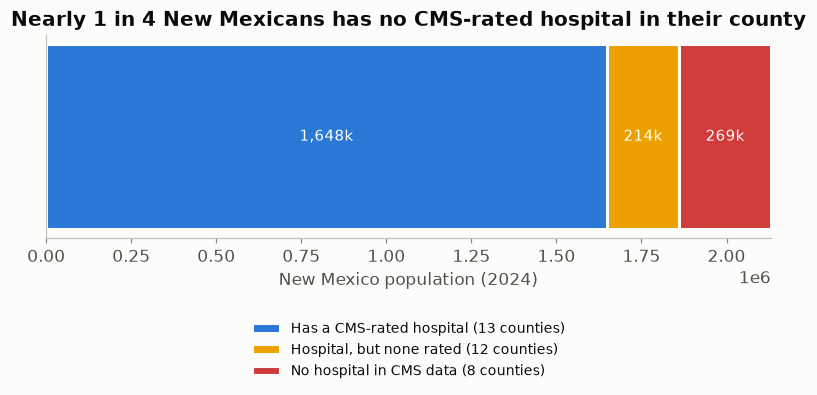

In [3]:
order = ["Has a CMS-rated hospital", "Hospital, but none rated", "No hospital in CMS data"]
colors = {"Has a CMS-rated hospital": BETTER,
          "Hospital, but none rated": CATEGORICAL[2],
          "No hospital in CMS data": WORSE}
s = summary.reindex(order)

fig, ax = plt.subplots(figsize=(8.5, 2.4))
left = 0
for label in order:
    val = s.loc[label, "population"]
    ax.barh(0, val, left=left, color=colors[label], edgecolor=SURFACE, linewidth=2,
            label=f"{label} ({int(s.loc[label,'counties'])} counties)")
    ax.text(left + val / 2, 0, f"{val/1000:,.0f}k", ha="center", va="center",
            color="white", fontsize=10)
    left += val
ax.set_xlim(0, total)
ax.set_yticks([])
ax.set_xlabel("New Mexico population (2024)")
ax.set_title("Nearly 1 in 4 New Mexicans has no CMS-rated hospital in their county")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.35), ncol=1, fontsize=9)
ax.grid(False)
fig.savefig(FIG / "fig_population_coverage.png")
plt.show()

## 3) Which counties, and how many people

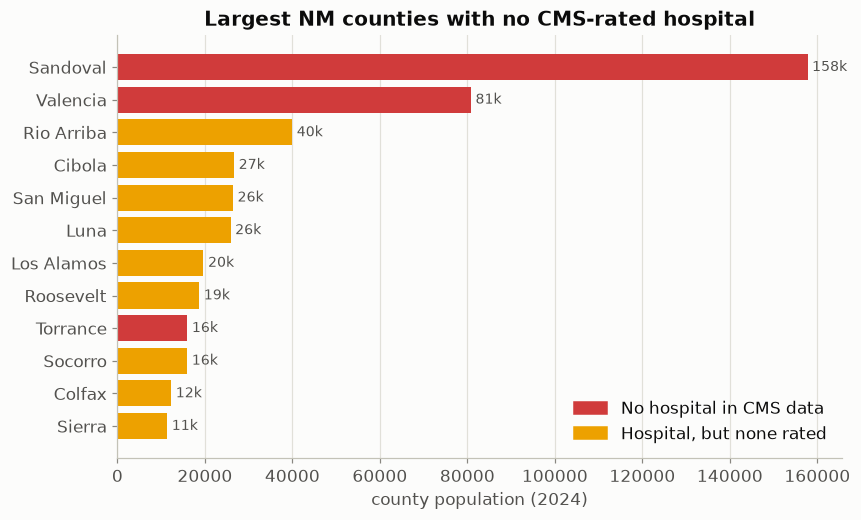

,county,pop,n_hosp,n_rated
0,SANDOVAL,157757,0.0,0.0
1,VALENCIA,80813,0.0,0.0
2,RIO ARRIBA,39955,1.0,0.0
3,CIBOLA,26686,1.0,0.0
4,SAN MIGUEL,26428,1.0,0.0
5,LUNA,25878,1.0,0.0
6,LOS ALAMOS,19675,1.0,0.0
7,ROOSEVELT,18713,1.0,0.0
8,TORRANCE,15986,0.0,0.0
9,SOCORRO,15967,1.0,0.0


In [4]:
gap = county[county["coverage"] != "Has a CMS-rated hospital"].sort_values("pop", ascending=False)

fig, ax = plt.subplots(figsize=(8.5, 5))
top = gap.head(12).iloc[::-1]
bar_colors = [colors[c] for c in top["coverage"]]
bars = ax.barh(top["county"].str.title(), top["pop"], color=bar_colors)
ax.bar_label(bars, labels=[f"{p/1000:.0f}k" for p in top["pop"]], padding=3, color=INK2, fontsize=9)
ax.set_xlabel("county population (2024)")
ax.set_title("Largest NM counties with no CMS-rated hospital")
ax.grid(axis="y", visible=False)
# legend proxies
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=WORSE, label="No hospital in CMS data"),
                   Patch(color=CATEGORICAL[2], label="Hospital, but none rated")],
          frameon=False, loc="lower right")
fig.savefig(FIG / "fig_gap_counties.png")
plt.show()
display(gap[["county", "pop", "n_hosp", "n_rated"]].reset_index(drop=True))

## Takeaway — people in the blind spots (question 2, in human terms)

- **About 482,000 New Mexicans (~23%) live in a county with no CMS-rated hospital**
  - either no hospital in the CMS data at all (269k, 8 counties) or only unrated hospitals
  (214k, 12 counties).
- **Caveat worth stating:** a few counties classed as "no hospital in CMS data" do have
  hospitals in reality (Sandoval / Rio Rancho) that simply are not in this CMS
  release - so even CMS's facility list has gaps, not just its measures.

**Final takeaway**: a CMS-only quality view is blind to roughly a quarter of the population. For members in these counties, a health plan needs its own claims data to see quality at all. CMS can only tell a plan where to act on hospitals it rates; for this 23% it rates nothing, so there isn't much that can be done with this blindspot from the CMS data.